# Ejercicio 2: relaciones entre variables

El mismo `viajes_taxi.csv` del Ejercicio 1. La última celda imprime una comprobación por cada `TODO`; no la modifiques. Completa los `TODO` hasta que las cinco digan `OK`, y después pasa a los hallazgos del README.

Corre todas las celdas una vez antes de empezar (**Run All**).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

viajes = pd.read_csv("viajes_taxi.csv")

## Paso 1: quitar solo los errores confirmados

In [2]:
# TODO 1: quita solo los errores que el Ejercicio 1 ya confirmo (tarifa
# 999.99 y duracion negativa). No quites los demas atipicos. Imprime
# cuantas filas quedan.
errores = (viajes["tarifa"] == 999.99) | (viajes["duracion_min"] < 0)
limpios = viajes[~errores].copy()
print(f"Filas tras quitar los errores confirmados: {len(limpios)}")

Filas tras quitar los errores confirmados: 2975


## Paso 2: distancia contra tarifa

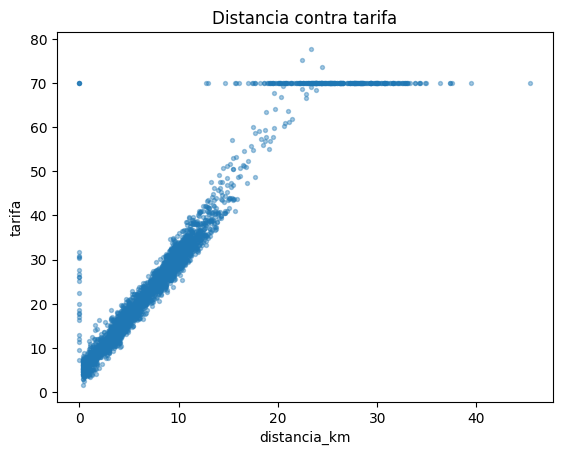

Viajes con tarifa exacta de 70: 300
JFK Airport -> Midtown            61
Midtown -> JFK Airport            56
JFK Airport -> Lower Manhattan    35
JFK Airport -> Upper West Side    33
JFK Airport -> Upper East Side    32
Name: count, dtype: int64
Viajes con distancia 0: 25


In [3]:
figura_dispersion = plt.figure()
# TODO 2: grafico de dispersion de distancia_km (eje x) contra tarifa
# (eje y). Mira el grafico antes de seguir: busca puntos que no sigan
# la tendencia general y cuentalos con un filtro.
plt.scatter(limpios["distancia_km"], limpios["tarifa"], s=8, alpha=0.4)
plt.title("Distancia contra tarifa")
plt.xlabel("distancia_km")
plt.ylabel("tarifa")
plt.show()

tarifa_fija = limpios[limpios["tarifa"] == 70]
print(f"Viajes con tarifa exacta de 70: {len(tarifa_fija)}")
print((tarifa_fija["zona_origen"] + " -> " + tarifa_fija["zona_destino"]).value_counts().head())
print(f"Viajes con distancia 0: {(limpios['distancia_km'] == 0).sum()}")

## Paso 3: propina por método de pago

In [4]:
# TODO 3: resumen_propina, con la propina promedio, la cantidad de viajes
# y la cantidad de viajes con propina 0, por metodo de pago.
resumen_propina = limpios.groupby("metodo_pago").agg(
    propina_promedio=("propina", "mean"),
    viajes=("propina", "size"),
    propina_cero=("propina", lambda p: (p == 0).sum()),
)
print(f"Viajes sin metodo de pago: {limpios['metodo_pago'].isna().sum()}")
resumen_propina

Viajes sin metodo de pago: 60


,propina_promedio,viajes,propina_cero
metodo_pago,,,
efectivo,0.000000,888,888
tarjeta,4.728762,2027,0


## Paso 4: correlaciones con la tarifa

In [5]:
# TODO 4: correlaciones, la correlacion de distancia_km, duracion_min,
# pasajeros y propina con la tarifa.
correlaciones = limpios[["distancia_km", "duracion_min", "pasajeros", "propina"]].corrwith(limpios["tarifa"])
correlaciones

distancia_km    0.960204
duracion_min    0.955923
pasajeros      -0.051145
propina         0.632852
dtype: float64

## Paso 5: pasajeros vacíos o en 0

In [6]:
# TODO 5: cuantos viajes tienen pasajeros vacio y cuantos tienen 0.
pasajeros_vacios = limpios["pasajeros"].isna().sum()
pasajeros_cero = (limpios["pasajeros"] == 0).sum()
print(f"Pasajeros vacio: {pasajeros_vacios}  Pasajeros en 0: {pasajeros_cero}")

Pasajeros vacio: 119  Pasajeros en 0: 19


## Comprobación

In [7]:
def comprobar(numero, condicion):
    if condicion:
        print(f"TODO {numero}: OK")
    else:
        print(f"TODO {numero}: revisa")


if isinstance(correlaciones, pd.DataFrame):
    correlaciones = correlaciones["tarifa"]

ejes = figura_dispersion.axes
comprobar(1, len(limpios) == 2975)
comprobar(2, len(ejes) > 0 and len(ejes[0].collections) > 0)
comprobar(3, resumen_propina is not None and len(resumen_propina) == 2)
comprobar(4, correlaciones is not None and round(float(correlaciones["distancia_km"]), 2) == 0.96)
comprobar(5, pasajeros_vacios == 119 and pasajeros_cero == 19)

TODO 1: OK
TODO 2: OK
TODO 3: OK
TODO 4: OK
TODO 5: OK
